/usr/local/lib/python3.12/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.12/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(


Discrete(1)
Discrete(10)
Estimates Q-values for each arm: [ 0.25  0.7  -1.21  0.56  1.13  0.4  -0.18  0.92  1.48  0.72]
Number of times each arm was selected [ 25  15   6   6  21  29   1   6 386   5]
Average reward over all episodes 1.26


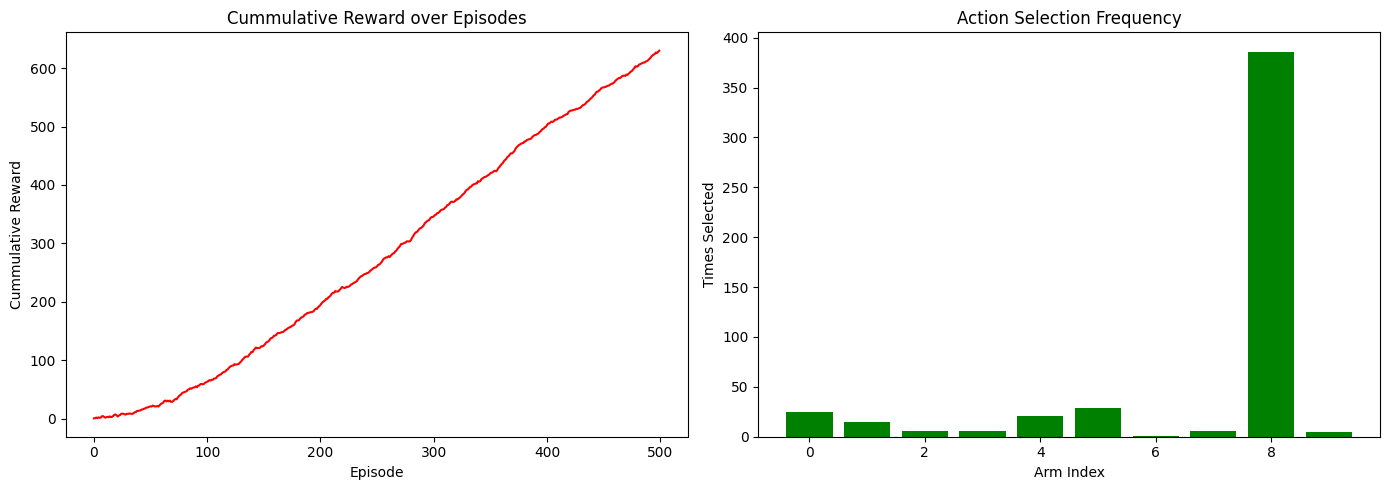

In [ ]:
import gym
import gym_bandits
import numpy as np
import warnings
import matplotlib.pyplot as plt

env=gym.make('MultiarmedBandits-v0', disable_env_checker=True)
print(env.observation_space)
print(env.action_space)

n_arms=env.action_space.n
num_episodes = 500
epsilon = 0.1

q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
reward_sums = np.zeros(n_arms)

all_rewards = []
action_history = []

warnings.filterwarnings("ignore", category = DeprecationWarning)
env.reset()

for episode in range(num_episodes):
  if np.random.rand() < epsilon:
    action = env.action_space.sample()
  else:
    action = np.argmax(q_values)

  observation, reward, done, info = env.step(action)
  counts[action] += 1
  # Fix: Convert reward array to scalar using .item()
  reward_sums[action] += reward.item()
  q_values[action] = reward_sums[action] / counts[action]

  all_rewards.append(reward.item()) # Append the scalar reward
  action_history.append(action)

env.close()

print("Estimates Q-values for each arm:", np.round(q_values, 2))
print("Number of times each arm was selected", counts.astype(int))
print("Average reward over all episodes", round(np.mean(all_rewards), 3))

plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(np.cumsum(all_rewards),color='red')
plt.title("Cummulative Reward over Episodes")
plt.xlabel("Episode")
plt.ylabel("Cummulative Reward")

plt.subplot(1,2,2)
plt.bar(np.arange(n_arms),counts,color='green')
plt.title("Action Selection Frequency")
plt.xlabel("Arm Index")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()